# 02 - Modelling, evaluation and error analysis

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C
show = lambda name: display(Image(filename=str(C.IMAGES / name)))

## Split and strategy

In [2]:
m = json.loads((C.REPORTS / 'metrics.json').read_text())
print(json.dumps(m['splits'], indent=1)); print(json.dumps(m['chosen'], indent=1))

{
 "train": [
  "2013-04-30",
  "2016-06-30"
 ],
 "validation": [
  "2016-07-01",
  "2017-03-31"
 ],
 "test": [
  "2017-04-01",
  "2017-12-31"
 ],
 "rows": {
  "train": 579000,
  "validation": 137000,
  "test": 137500
 }
}
{
 "target": "ratio",
 "objective": "regression_l1",
 "num_leaves": 63,
 "best_iteration_on_validation": 101,
 "rounds_train_plus_val": 116,
 "rounds_all_history": 121
}


Chronological split, about 70% / 15% / 15%. The forecast is **direct**, 28 days ahead: every feature for a target day uses only data from at least 28 days earlier, so any day in the next 28 can be forecast at the origin. Validation drives tuning. Final models are refit on train+validation before touching the test period.

In [3]:
from src import features as F
df = pd.read_parquet(C.PROCESSED / 'daily_sales.parquet')
sub = df[(df.store <= 2) & (df.item <= 3)]
print('Leakage check (future data perturbed, features unchanged):', F.leakage_check(sub, '2016-09-15'))
print(F.verify_row(F.build(df), df, '2016-09-15', 3, 7))

Leakage check (future data perturbed, features unchanged): (True, 0.0)


{'lag_28': (57.0, 57.0, True), 'roll_mean_28': (87.96428680419922, 87.96428680419922, True), 'dow_mean_5': (80.80000305175781, 80.80000305175781, True)}


## Tuning on validation

In [4]:
pd.DataFrame(m['tuning'])

,target,objective,num_leaves,best_iteration,val_MAE,seconds
0,raw,regression,63,522,5.906798,44.055218
1,raw,regression_l1,63,927,5.912475,80.481162
2,ratio,regression_l1,63,101,5.803050,33.479291
3,ratio,regression_l1,127,98,5.811991,37.081546


Predicting the ratio to the 91-day level (weighted L1, equal to optimising MAE) beat predicting raw units, because it lets the trees handle growth they never saw.

## Model comparison

In [5]:
rows = []
for split in ('validation', 'test'):
    for name, v in m[split].items():
        if not name.startswith('_'):
            rows.append({'split': split, 'model': name, **{k: round(x, 3) for k, x in v.items()}})
pd.DataFrame(rows)

,split,model,MAE,RMSE,sMAPE,WAPE,Bias,R2
0,validation,Seasonal naive (last same weekday),9.226,12.212,18.920,16.859,1.384,0.829
1,validation,"Seasonal naive (same weekday, 28 days earlier)",10.100,13.383,20.423,18.456,1.558,0.795
2,validation,Moving average (28 days),9.816,13.005,19.211,17.937,1.674,0.807
3,validation,Random Forest,6.081,7.920,12.852,11.113,0.471,0.928
4,validation,LightGBM,5.803,7.530,12.362,10.605,0.212,0.935
5,test,Seasonal naive (last same weekday),9.736,12.789,17.516,15.436,-0.601,0.846
6,test,"Seasonal naive (same weekday, 28 days earlier)",10.770,14.165,19.026,17.075,0.895,0.811
7,test,Moving average (28 days),10.567,13.899,17.972,16.753,0.612,0.818
8,test,Random Forest,6.496,8.439,11.804,10.300,0.550,0.933
9,test,LightGBM,6.198,8.026,11.350,9.827,0.225,0.939


In [6]:
print(json.dumps(m['timing'], indent=1))
print(json.dumps(json.loads((C.REPORTS / 'ets_comparison.json').read_text())['like_for_like']['test'], indent=1)[:1500])

{
 "LightGBM": {
  "train_seconds": 33.47929120063782
 },
 "Random Forest": {
  "train_seconds": 65.66641521453857
 }
}
{
 "Seasonal naive (last same weekday)": {
  "MAE": 9.873030303030303,
  "RMSE": 12.909904583831608,
  "sMAPE": 17.226853727370685,
  "WAPE": 15.157478483368225,
  "Bias": -0.6578787878787878,
  "R2": 0.8393698627144406
 },
 "Exponential smoothing (Holt-Winters)": {
  "MAE": 8.047985325437603,
  "RMSE": 10.584459933980597,
  "sMAPE": 13.886120606241445,
  "WAPE": 12.355595056498764,
  "Bias": -0.2743670276295055,
  "R2": 0.8920262034399671
 },
 "Random Forest": {
  "MAE": 6.574491886023319,
  "RMSE": 8.489883477850704,
  "sMAPE": 11.655310207431828,
  "WAPE": 10.093427878053944,
  "Bias": 0.5738779236764618,
  "R2": 0.9305320592821795
 },
 "LightGBM": {
  "MAE": 6.316636072794596,
  "RMSE": 8.138456941641945,
  "sMAPE": 11.259952170253147,
  "WAPE": 9.697557125016127,
  "Bias": 0.20463941065470378,
  "R2": 0.9361640823447572
 }
}


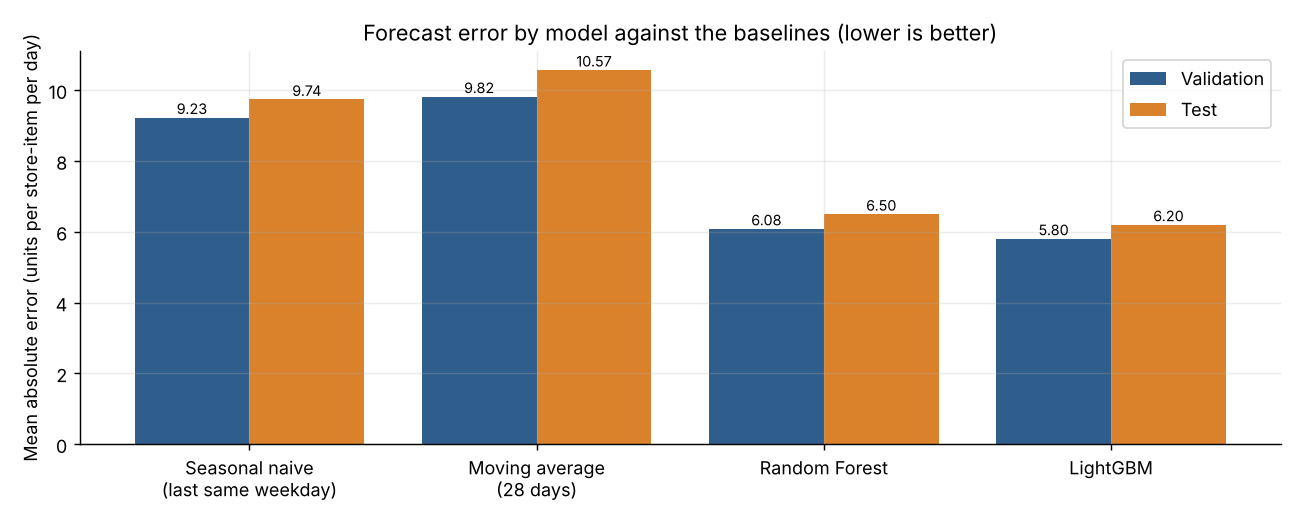

In [7]:
show('11_model_comparison.png')

LightGBM reaches a test MAE of 6.20 against 9.74 for the strongest baseline (last same weekday), a 36% reduction. Random Forest is close (6.50). Holt-Winters, run per series on a 60-series sample, scores 8.05 against 6.32 for LightGBM on the same series, because it cannot see the annual cycle in a 730-day window.

## Forecast and uncertainty

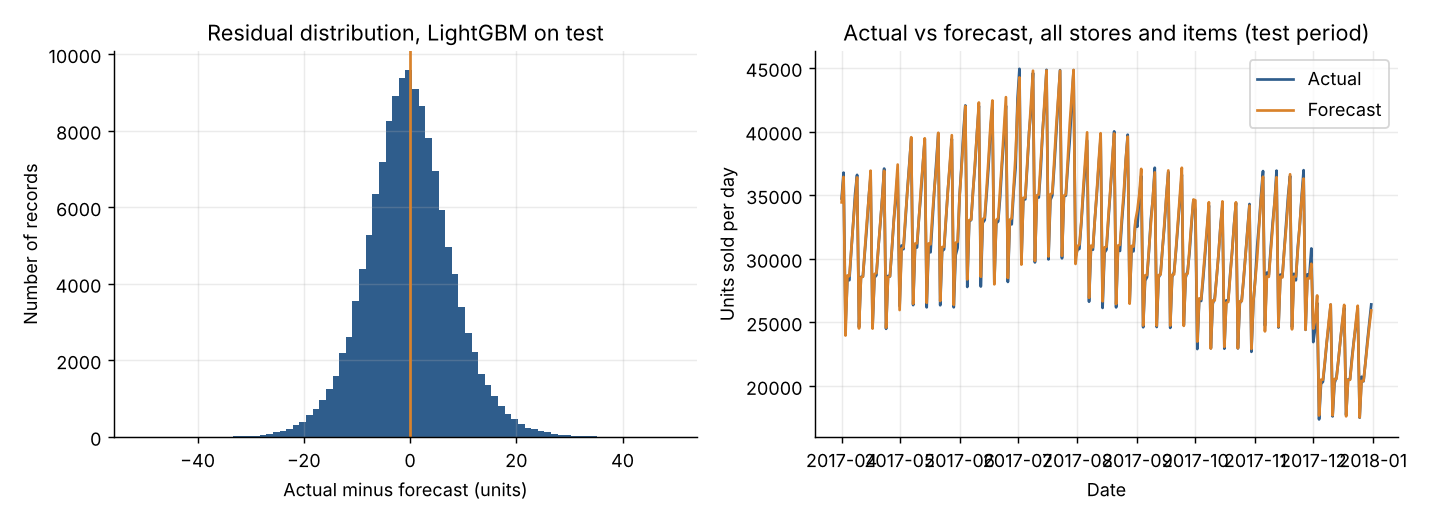

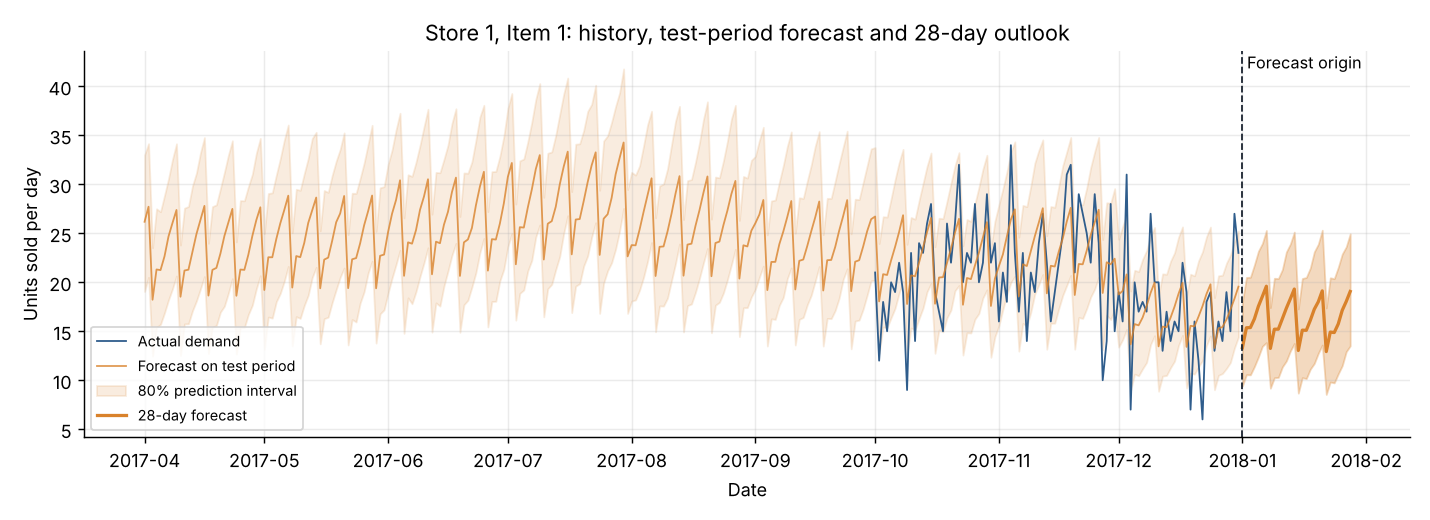

In [8]:
show('12_actual_vs_forecast_total.png'); show('13_forecast_example.png')

In [9]:
m['test']['_interval_80']

{'coverage': 0.8000436363636364, 'avg_width': 20.004975641799373}

The 80% interval from two quantile models covers 80.0% of test records, so it is well calibrated, and its average width is 20 units. At total level the forecast error is under 1% of volume.

## Error analysis

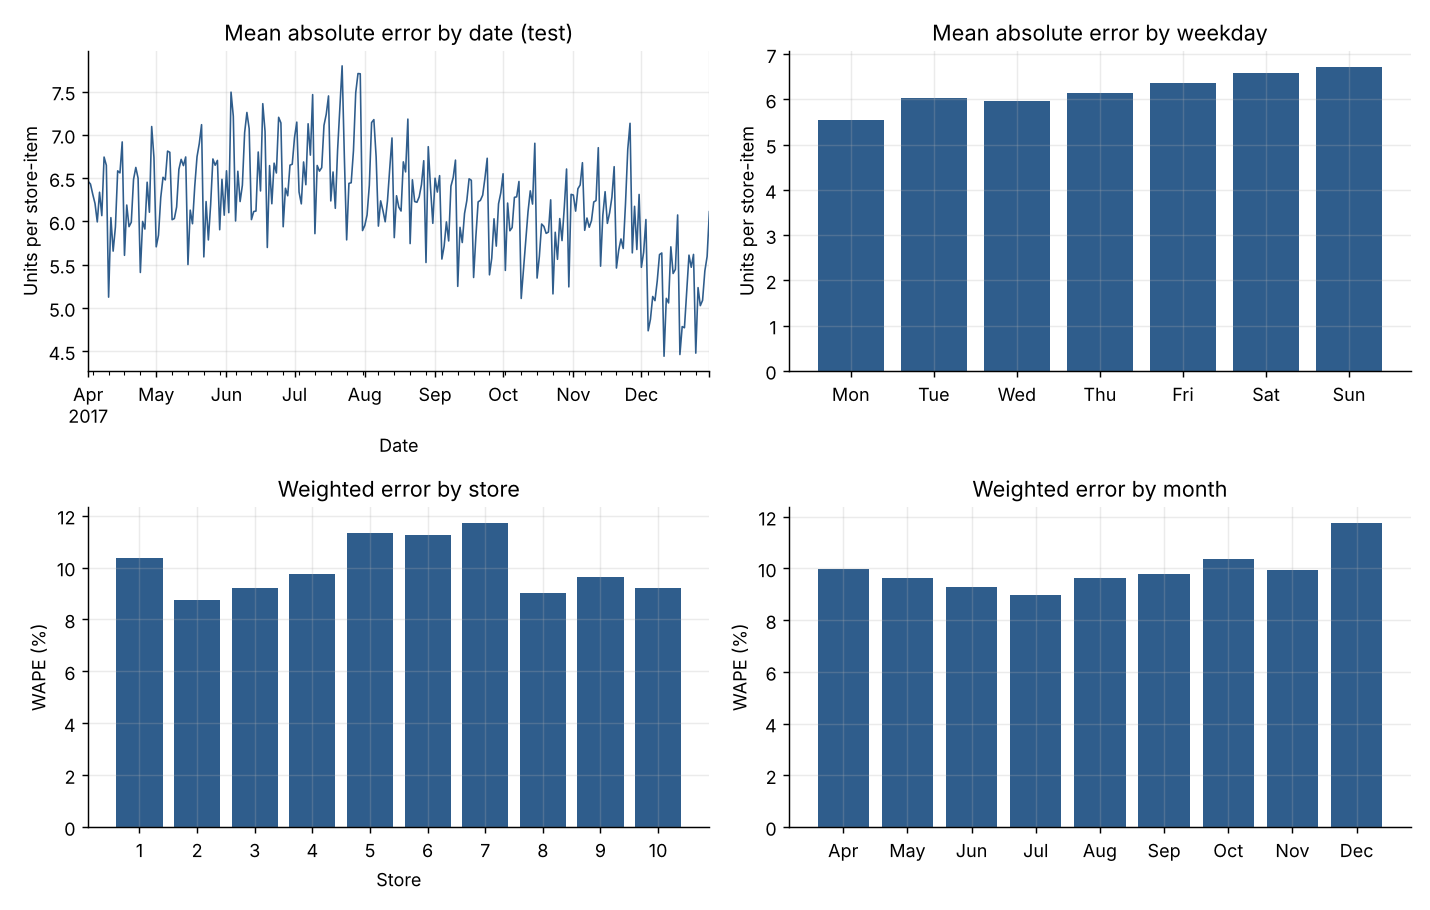

{
 "worst_dates": {
  "2017-07-22": 7.796489715576172,
  "2017-07-29": 7.707508563995361,
  "2017-07-30": 7.704782009124756,
  "2017-06-03": 7.492596626281738,
  "2017-07-28": 7.486021041870117,
  "2017-07-09": 7.464498519897461,
  "2017-07-16": 7.449075222015381,
  "2017-06-17": 7.359685897827148,
  "2017-07-21": 7.302062034606934,
  "2017-06-10": 7.258011341094971
 },
 "worst_items_wape": {
  "5": 16.650915145874023,
  "4": 16.032608032226562,
  "41": 15.604618072509766,
  "27": 15.420036315917969,
  "47": 15.412571907043457
 },
 "best_items_wape": {
  "18": 7.957748889923096,
  "28": 7.776731967926025,
  "15": 7.697519779205322
 },
 "store_wape": {
  "7": 11.726609230041504,
  "5": 11.324482917785645,
  "6": 11.254857063293457,
  "1": 10.37588119506836,
  "4": 9.757843971252441,
  "9": 9.629576683044434,
  "10": 9.227396965026855,
  "3": 9.202123641967773,
  "8": 9.021529197692871,
  "2": 8.743247032165527
 },
 "dow_wape": {
  "Mon": 11.053168296813965,
  "Tue": 10.339560508728027,


In [10]:
show('14_error_analysis.png')
print(json.dumps(json.loads((C.REPORTS / 'error_findings.json').read_text())['errors'], indent=1)[:2500])

**Where it fails:** summer weekends (June and July) have the largest absolute errors because volume is highest; December and Mondays have the highest relative error; stores 7, 5 and 6 and items 5, 4 and 41 have the highest WAPE because they are the lowest-volume series. **Why:** low-volume series carry more relative noise, and the model only sees calendar and past sales, with no price, promotion, weather or stock data. **What would help:** a promotion and price calendar, local weather, and stock availability flags to separate stockouts from low demand; each would be validated by adding it as a feature and re-running the same chronological test. Validation also showed the model over-forecasting January to March 2017 by about 2%, so the January 2018 growth figure should be read with that bias in mind.

In [11]:
pd.read_csv(C.REPORTS / 'feature_importance.csv').head(10)

,feature,gain,gain_share
0,woy,1.464731e+08,0.459466
1,dow,7.344026e+07,0.230372
2,month,6.330018e+07,0.198564
3,doy,1.579371e+07,0.049543
4,is_weekend,7.177887e+06,0.022516
5,item,2.290567e+06,0.007185
6,dom,2.113600e+06,0.006630
7,trend_ratio,2.099157e+06,0.006585
8,lag_28,1.193473e+06,0.003744
9,days_to_holiday,6.788187e+05,0.002129
